# RBIG Demo

In [1]:
!pip install python-picard
!pip install "git+https://github.com/IPL-UV/rbig.git"

import numpy as np
import warnings
from time import time

# from rbig.model import RBIG
from sklearn.model_selection import train_test_split
from sklearn.utils import check_random_state
import matplotlib.pyplot as plt
plt.style.use('ggplot')
warnings.filterwarnings('ignore') # get rid of annoying warnings

%matplotlib inline
%load_ext autoreload
%autoreload 2

  Cloning https://github.com/IPL-UV/rbig.git to /tmp/pip-req-build-uvorzwqv
  Running command git clone -q https://github.com/IPL-UV/rbig.git /tmp/pip-req-build-uvorzwqv


#### Penguins Data

In [2]:
import tensorflow.keras.datasets.cifar10 as cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

In [3]:
x_train.shape

(50000, 32, 32, 3)

In [4]:
x_train = x_train[:,4:-5:2,4:-5:2,0]

In [67]:
x_test = x_test[:,4:-5:2,4:-5:2,0]

In [5]:
x_train.shape

(50000, 12, 12)

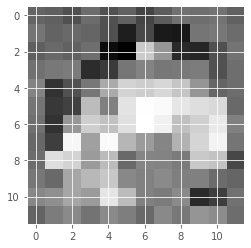

In [6]:
import matplotlib.pyplot as plt
plt.imshow(x_train[0,:,:],cmap='gray')

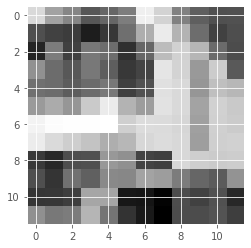

In [7]:
import matplotlib.pyplot as plt
plt.imshow(x_train[1,:,:],cmap='gray')

In [8]:
x_train.shape

(50000, 12, 12)

In [9]:
y_train==0

array([[False],
       [False],
       [False],
       ...,
       [False],
       [False],
       [False]])

In [10]:
x_train_0 = x_train[y_train[:,0]==0,:,:]
x_train_1 = x_train[y_train[:,0]==1,:,:]

In [68]:
x_test_0 = x_test[y_test[:,0]==0,:,:]
x_test_1 = x_test[y_test[:,0]==1,:,:]

In [11]:
x_train_0 = np.reshape(x_train_0,(x_train_0.shape[0],x_train_0.shape[1]*x_train_0.shape[2]))/255
x_train_1 = np.reshape(x_train_1,(x_train_1.shape[0],x_train_1.shape[1]*x_train_1.shape[2]))/255

In [69]:
x_test_0 = np.reshape(x_test_0,(x_test_0.shape[0],x_test_0.shape[1]*x_test_0.shape[2]))/255
x_test_1 = np.reshape(x_test_1,(x_test_1.shape[0],x_test_1.shape[1]*x_test_1.shape[2]))/255

In [66]:
x_test_0.shape

(1000, 32, 32, 3)

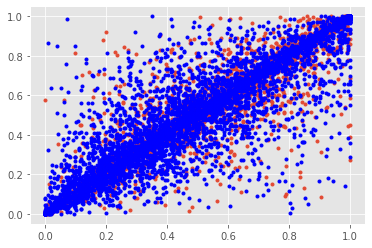

In [13]:
plt.plot(x_train_0[:,1],x_train_0[:,2],'.')
plt.plot(x_train_1[:,1],x_train_1[:,2],'b.')

## RBIG Fitting

In [14]:
from rbig import RBIG

In [15]:
# Initialize RBIG class
rot = 'pca' # 'random','pca', 'ica'

rbig_model_0 = RBIG(bound_ext = 0.3, rotation=rot)
rbig_model_1 = RBIG(bound_ext = 0.3, rotation=rot)

# transform data
data_trans_0 = rbig_model_0.fit_transform(x_train_0)
data_trans_1 = rbig_model_1.fit_transform(x_train_1)

Completed! (Total Info Red: 214.1959):   6%|▌         | 61/1000 [01:01<15:54,  1.02s/it]


### Transform Data into Gaussian

(5000, 144)


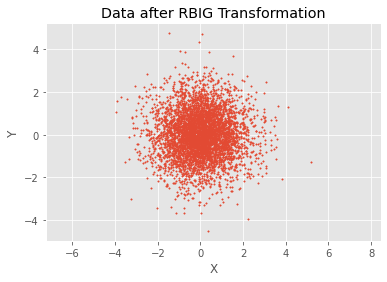

In [17]:
print(data_trans_0.shape)
fig, ax = plt.subplots()
ax.scatter(data_trans_0[:, 0], data_trans_0[:, 1], s=2)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Data after RBIG Transformation')
ax.axis('equal')
plt.show()

In [18]:
data_trans_0[:, 0]

array([ 3.0443767 , -0.74870131, -0.32097909, ...,  1.28852712,
        0.83192864, -2.2627964 ])

### Information Reduction

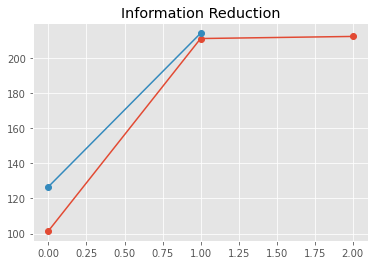

In [22]:

fig, ax = plt.subplots()
ax.plot(np.cumsum(rbig_model_0.info_loss),'o-')
ax.plot(np.cumsum(rbig_model_1.info_loss),'o-')
ax.set_title('Information Reduction')
plt.show()

### Generated Synthetic Data

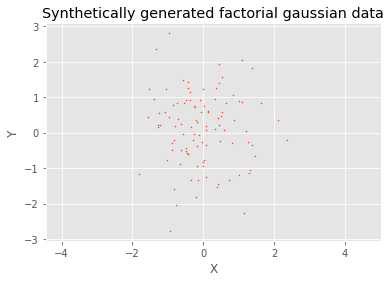

In [25]:
data_synthetic = np.random.randn(100,x_train_0.shape[1])

fig, ax = plt.subplots()
ax.scatter(data_synthetic[:, 0], data_synthetic[:, 1], s=1)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Synthetically generated factorial gaussian data')
ax.axis('equal')
plt.show()

### Synthesize New Data from RBIG Model

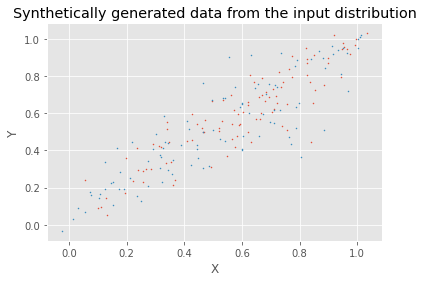

In [26]:
data_synthetic_0 = rbig_model_0.inverse_transform(data_synthetic)
data_synthetic_1 = rbig_model_1.inverse_transform(data_synthetic)

fig, ax = plt.subplots()
ax.scatter(data_synthetic_0[:, 0], data_synthetic_0[:, 1], s=1)
ax.scatter(data_synthetic_1[:, 0], data_synthetic_1[:, 1], s=1)
# ax.scatter(data[:, 0], data[:, 1], s=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Synthetically generated data from the input distribution')
plt.show()

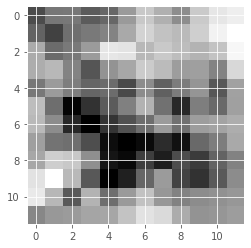

In [49]:
# Imagen syntetica de la clase 0
plt.figure
plt.imshow(np.reshape(data_synthetic_0[0,:],x_train.shape[1:]),cmap='gray')

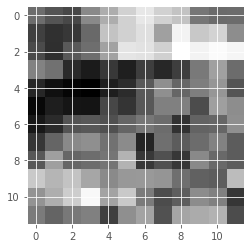

In [50]:
# Imagen syntetica de la clase 1
plt.figure
plt.imshow(np.reshape(data_synthetic_1[0,:],x_train.shape[1:]),cmap='gray')

# Estimate probabilities

### Con las muestras de train

In [84]:
# 

# Probabilidad de las muestras 0 en el modelo 0
pX0_en_m0 = rbig_model_0.predict_proba(x_train_0[0:100,:])
# Probabilidad de las muestras 1 en el modelo 0
pX1_en_m0 = rbig_model_0.predict_proba(x_train_1[0:100,:])
# Probabilidad de las muestras 0 en el modelo 1
pX0_en_m1 = rbig_model_1.predict_proba(x_train_0[0:100,:])
# Probabilidad de las muestras 1 en el modelo 1
pX1_en_m1 = rbig_model_1.predict_proba(x_train_1[0:100,:])

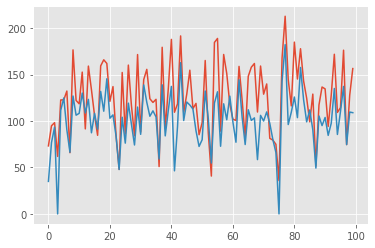

In [85]:
plt.plot(np.log(pX0_en_m0+1))
plt.plot(np.log(pX0_en_m1+1))

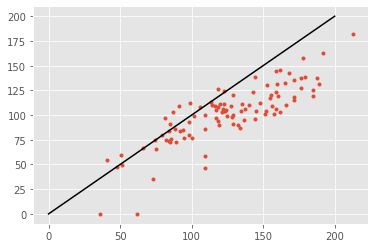

In [86]:
plt.plot(np.log(pX0_en_m0+1),np.log(pX0_en_m1+1),'.')
plt.plot([0,200],[0,200],'k-')

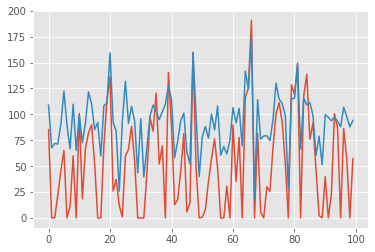

In [87]:
plt.plot(np.log(pX1_en_m0+1))
plt.plot(np.log(pX1_en_m1+1))

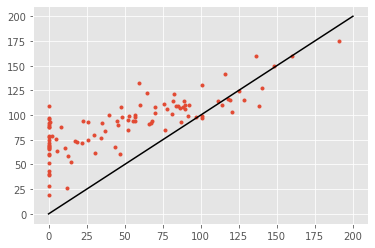

In [88]:
plt.plot(np.log(pX1_en_m0+1),np.log(pX1_en_m1+1),'.')
plt.plot([0,200],[0,200],'k-')

### Con las muestras de sintéticas

In [89]:


# Probabilidad de las muestras 0 en el modelo 0
pX0_en_m0 = rbig_model_0.predict_proba(data_synthetic_0)
# Probabilidad de las muestras 1 en el modelo 0
pX1_en_m0 = rbig_model_0.predict_proba(data_synthetic_1)
# Probabilidad de las muestras 0 en el modelo 1
pX0_en_m1 = rbig_model_1.predict_proba(data_synthetic_0)
# Probabilidad de las muestras 1 en el modelo 1
pX1_en_m1 = rbig_model_1.predict_proba(data_synthetic_1)

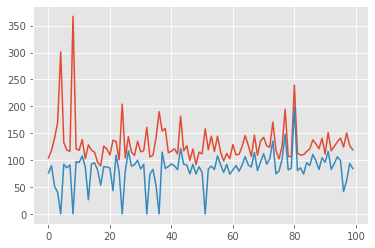

In [90]:
plt.plot(np.log(pX0_en_m0+1))
plt.plot(np.log(pX0_en_m1+1))

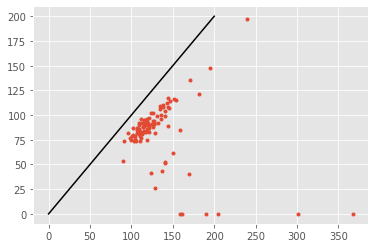

In [91]:
plt.plot(np.log(pX0_en_m0+1),np.log(pX0_en_m1+1),'.')
plt.plot([0,200],[0,200],'k-')

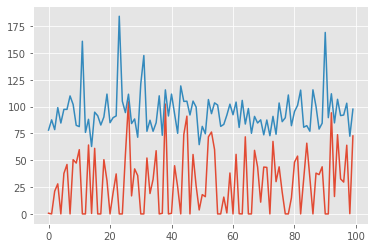

In [92]:
plt.plot(np.log(pX1_en_m0+1))
plt.plot(np.log(pX1_en_m1+1))

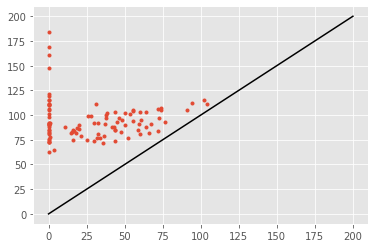

In [93]:
plt.plot(np.log(pX1_en_m0+1),np.log(pX1_en_m1+1),'.')
plt.plot([0,200],[0,200],'k-')

### Con las muestras de test

In [94]:
# 

# Probabilidad de las muestras 0 en el modelo 0
pX0_en_m0 = rbig_model_0.predict_proba(x_test_0[0:100,:])
# Probabilidad de las muestras 1 en el modelo 0
pX1_en_m0 = rbig_model_0.predict_proba(x_test_1[0:100,:])
# Probabilidad de las muestras 0 en el modelo 1
pX0_en_m1 = rbig_model_1.predict_proba(x_test_0[0:100,:])
# Probabilidad de las muestras 1 en el modelo 1
pX1_en_m1 = rbig_model_1.predict_proba(x_test_1[0:100,:])

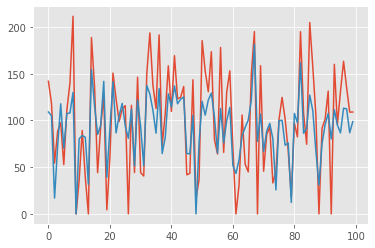

In [95]:
plt.plot(np.log(pX0_en_m0+1))
plt.plot(np.log(pX0_en_m1+1))

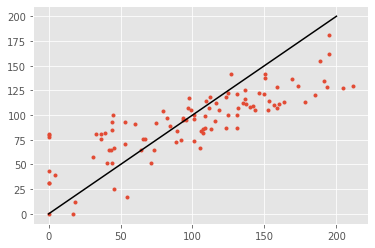

In [96]:
plt.plot(np.log(pX0_en_m0+1),np.log(pX0_en_m1+1),'.')
plt.plot([0,200],[0,200],'k-')

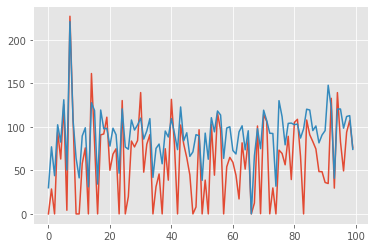

In [97]:
plt.plot(np.log(pX1_en_m0+1))
plt.plot(np.log(pX1_en_m1+1))

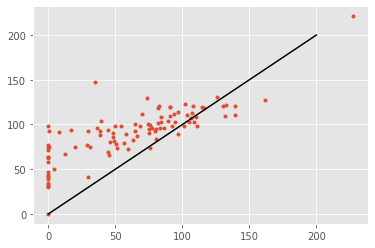

In [98]:
plt.plot(np.log(pX1_en_m0+1),np.log(pX1_en_m1+1),'.')
plt.plot([0,200],[0,200],'k-')